# StableNet 医学影像对比实验

本 notebook 按四个阶段组织：**图片处理 → 训练前设置 → 两种方法训练与模型筛选 → 同图 Grad-CAM 对比**。

模型选择只使用验证集：每种方法运行多个随机种子，每次运行先选择验证准确率最高的 epoch；全部运行结束后仅保留验证结果最好的两次运行所对应的模型。测试集只用于最终评价，不参与模型筛选。

## 第一阶段：图片处理

本阶段把原始脑出血或脑肿瘤图片整理为 `train/val/test` 与 `negative/positive` 目录。数据已经整理好时保持 `REBUILD_DATASET=False`，代码只检查数量；只有确实需要重建时才改为 `True`。

In [1]:
from pathlib import Path
import random
import shutil
import pandas as pd

ROOT = Path("/root/autodl-tmp")
RAW_ROOT = ROOT / "medical_raw"
OUTPUT_ROOT = ROOT / "medical_data"

# 可选："hemorrhage" 或 "tumor"
TASK = "tumor"
SPLIT_SEED = 42
REBUILD_DATASET = False


def split_files(files, seed=SPLIT_SEED, train_ratio=0.70, val_ratio=0.15):
    files = sorted(files)
    random.Random(seed).shuffle(files)
    n = len(files)
    n_train = int(n * train_ratio)
    n_val = int(n * val_ratio)
    return {
        "train": files[:n_train],
        "val": files[n_train:n_train + n_val],
        "test": files[n_train + n_val:],
    }


def create_link(source, destination):
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.is_symlink():
        destination.unlink()
    elif destination.exists():
        return
    destination.symlink_to(source)


def rebuild_hemorrhage_dataset():
    raw_root = RAW_ROOT / "brain_hemorrhage"
    image_root = raw_root / "head_ct" / "head_ct"
    labels = pd.read_csv(raw_root / "labels.csv")
    labels.columns = labels.columns.str.strip()
    output_root = OUTPUT_ROOT / "brain_hemorrhage"

    if output_root.exists():
        shutil.rmtree(output_root)

    class_files = {"negative": [], "positive": []}
    for _, row in labels.iterrows():
        image_path = image_root / f"{int(row['id']):03d}.png"
        if image_path.is_file():
            class_name = "positive" if int(row["hemorrhage"]) == 1 else "negative"
            class_files[class_name].append(image_path)

    for class_index, (class_name, files) in enumerate(class_files.items()):
        splits = split_files(files, seed=SPLIT_SEED + class_index)
        for stage, stage_files in splits.items():
            for source in stage_files:
                create_link(source, output_root / stage / class_name / source.name)


def rebuild_tumor_dataset():
    raw_root = RAW_ROOT / "brain_tumor"
    output_root = OUTPUT_ROOT / "brain_tumor"

    if output_root.exists():
        shutil.rmtree(output_root)

    source_classes = {
        "negative": raw_root / "no",
        "positive": raw_root / "yes",
    }

    for class_index, (class_name, source_dir) in enumerate(source_classes.items()):
        files = [
            path for path in source_dir.iterdir()
            if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ]
        splits = split_files(files, seed=SPLIT_SEED + class_index)
        for stage, stage_files in splits.items():
            for source in stage_files:
                create_link(source, output_root / stage / class_name / source.name)


if REBUILD_DATASET:
    if TASK == "hemorrhage":
        rebuild_hemorrhage_dataset()
    elif TASK == "tumor":
        rebuild_tumor_dataset()
    else:
        raise ValueError("TASK 只能是 hemorrhage 或 tumor")

DATA_DIR = OUTPUT_ROOT / ("brain_hemorrhage" if TASK == "hemorrhage" else "brain_tumor")

print("任务：", TASK)
print("数据目录：", DATA_DIR)
print("是否重建：", REBUILD_DATASET)

for stage in ("train", "val", "test"):
    for class_name in ("negative", "positive"):
        folder = DATA_DIR / stage / class_name
        count = len([p for p in folder.glob("*") if p.is_file()])
        print(f"{stage:5s} / {class_name:8s}: {count}")

任务： tumor
数据目录： /root/autodl-tmp/medical_data/brain_tumor
是否重建： False
train / negative: 1050
train / positive: 1050
val   / negative: 225
val   / positive: 225
test  / negative: 225
test  / positive: 225


## 第二阶段：训练前设置

本阶段统一设置数据集、训练轮数、随机种子和输出位置，并检查类别映射。实验同时运行普通 ResNet18（StableNet 关闭）和 StableNet（从第一个 epoch 开启），两者使用完全相同的数据划分、预处理和随机种子。

In [2]:
import os
import sys
import re
import time
import subprocess
import numpy as np
import torch
from pathlib import Path
import random
import shutil
import pandas as pd


from torchvision.datasets import ImageFolder

PROJECT_DIR = Path("/root/autodl-tmp/train")
os.chdir(PROJECT_DIR)

TASK_CONFIG = {
    "hemorrhage": {
        "dataset_name": "BrainHemorrhage",
        "data_dir": OUTPUT_ROOT / "brain_hemorrhage",
    },
    "tumor": {
        "dataset_name": "BrainTumor",
        "data_dir": OUTPUT_ROOT / "brain_tumor",
    },
}

DATASET_NAME = TASK_CONFIG[TASK]["dataset_name"]
DATA_DIR = Path(TASK_CONFIG[TASK]["data_dir"])
NUM_CLASSES = 2

EPOCHS = 30
BATCH_SIZE = 16 if TASK == "hemorrhage" else 64
N_FEATURE = BATCH_SIZE
GPU = 0

SEEDS = [1, 3, 7, 21, 42]
KEEP_TOP_RUNS = 2

LR = 0.01
WEIGHT_DECAY = 0.0001
LRBL = 1.0
LAMBDAP = 70.0
EPOCHB = 20

METHODS = {
    # epochp >= epochs：关闭 StableNet
    "ResNet18_ERM": EPOCHS + 1,
    # epochp = 0：从第一个 epoch 开启 StableNet
    "StableNet": 0,
}

# 使用新目录，避免与以前实验的 checkpoint 混淆
RUN_ROOT = PROJECT_DIR / "results_method_comparison_v1" / DATASET_NAME
RUN_ROOT.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("训练配置")
print("=" * 70)
print("数据集：", DATASET_NAME)
print("数据目录：", DATA_DIR)
print("方法：", list(METHODS))
print("随机种子：", SEEDS)
print("每种方法最终保留模型数：", KEEP_TOP_RUNS)
print("输出目录：", RUN_ROOT)
print("GPU：", torch.cuda.get_device_name(GPU) if torch.cuda.is_available() else "CPU")
print("=" * 70)

训练配置
数据集： BrainTumor
数据目录： /root/autodl-tmp/medical_data/brain_tumor
方法： ['ResNet18_ERM', 'StableNet']
随机种子： [1, 3, 7, 21, 42]
每种方法最终保留模型数： 2
输出目录： /root/autodl-tmp/train/results_method_comparison_v1/BrainTumor
GPU： NVIDIA RTX 6000D


In [3]:
train_dataset_check = ImageFolder(DATA_DIR / "train")
val_dataset_check = ImageFolder(DATA_DIR / "val")
test_dataset_check = ImageFolder(DATA_DIR / "test")

assert train_dataset_check.class_to_idx == {"negative": 0, "positive": 1}
assert train_dataset_check.class_to_idx == val_dataset_check.class_to_idx
assert train_dataset_check.class_to_idx == test_dataset_check.class_to_idx

print("类别映射：", train_dataset_check.class_to_idx)
print("训练集：", len(train_dataset_check))
print("验证集：", len(val_dataset_check))
print("测试集：", len(test_dataset_check))

# 原始 main_stablenet.py 必须启用 checkpoint 保存。
main_source = (PROJECT_DIR / "main_stablenet.py").read_text(encoding="utf-8")
active_save_lines = [
    line for line in main_source.splitlines()
    if "save_checkpoint(" in line and not line.lstrip().startswith("#")
]


类别映射： {'negative': 0, 'positive': 1}
训练集： 2100
验证集： 450
测试集： 450


## 第三阶段：训练、评价与模型筛选

每种方法分别使用 5 个随机种子训练。每次运行根据验证准确率选择最佳 epoch，再进行一次最终测试。全部运行结束后，每种方法仅保留验证表现最好的两次运行所对应的最佳 epoch 模型；其他 checkpoint 会从本实验专用目录中删除，训练日志和结果表仍会保留。

In [4]:
from types import SimpleNamespace
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


def remove_module_prefix(state_dict):
    return {
        key.removeprefix("module."): value
        for key, value in state_dict.items()
    }


def load_checkpoint_model(checkpoint_path):
    import models

    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    state_dict = remove_module_prefix(checkpoint["state_dict"])

    if "pre_features" in state_dict:
        n_feature, feature_dim = state_dict["pre_features"].shape[:2]
    else:
        n_feature, feature_dim = N_FEATURE, 512

    model_args = SimpleNamespace(
        n_feature=n_feature,
        feature_dim=feature_dim,
        n_levels=1,
    )
    model = models.resnet18_with_table(pretrained=False, args=model_args)
    model.fc1 = nn.Linear(model.fc1.in_features, NUM_CLASSES)
    model.load_state_dict(state_dict, strict=False)

    device = torch.device(f"cuda:{GPU}" if torch.cuda.is_available() else "cpu")
    model = model.to(device).eval()
    return model, checkpoint, device


@torch.no_grad()
def evaluate_checkpoint(checkpoint_path):
    model, checkpoint, device = load_checkpoint_model(checkpoint_path)
    dataset = ImageFolder(DATA_DIR / "test", transform=test_transform)
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=4,
        pin_memory=True,
    )

    labels_all, predictions_all, probabilities_all = [], [], []
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        output = model(images)
        logits = output[0] if isinstance(output, tuple) else output
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        predictions = logits.argmax(dim=1)
        labels_all.extend(labels.numpy().tolist())
        predictions_all.extend(predictions.cpu().numpy().tolist())
        probabilities_all.extend(probabilities.cpu().numpy().tolist())

    y_true = np.asarray(labels_all)
    y_pred = np.asarray(predictions_all)
    y_prob = np.asarray(probabilities_all)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    try:
        roc_auc = 100 * roc_auc_score(y_true, y_prob)
    except ValueError:
        roc_auc = np.nan

    return {
        "accuracy": 100 * accuracy_score(y_true, y_pred),
        "balanced_accuracy": 100 * balanced_accuracy_score(y_true, y_pred),
        "sensitivity": 100 * recall_score(y_true, y_pred, zero_division=0),
        "specificity": 100 * tn / (tn + fp) if (tn + fp) else np.nan,
        "precision": 100 * precision_score(y_true, y_pred, zero_division=0),
        "f1": 100 * f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


def parse_epoch_results(raw_output):
    matches = re.findall(
        r"\*\s+Acc@1\s+([-\d.]+)\s+Acc@(?:2|5)\s+([-\d.]+)",
        raw_output,
    )
    rows = []
    for index in range(0, len(matches), 2):
        if index + 1 >= len(matches):
            break
        rows.append({
            "epoch": index // 2 + 1,
            "val_accuracy": float(matches[index][0]),
            "test_accuracy_during_training": float(matches[index + 1][0]),
        })
    return rows


def find_checkpoint_for_epoch(checkpoint_dir, target_epoch):
    candidates = sorted(Path(checkpoint_dir).glob("*.pth.tar"))
    matches = []
    for path in candidates:
        try:
            checkpoint = torch.load(path, map_location="cpu", weights_only=False)
            if int(checkpoint.get("epoch", -1)) == int(target_epoch):
                matches.append(path)
        except Exception:
            continue

    if not matches:
        raise FileNotFoundError(
            f"找不到 epoch={target_epoch} 的 checkpoint；目录：{checkpoint_dir}"
        )

    # 优先使用明确的逐 epoch 文件，而不是可能被旧逻辑覆盖的 model_best。
    matches.sort(key=lambda path: (path.name == "model_best.pth.tar", path.name))
    return matches[0]

In [5]:
all_results = []
failed_runs = []

for method_name, epochp in METHODS.items():
    for run_index, seed in enumerate(SEEDS, start=1):
        print("\n" + "=" * 76)
        print(f"方法：{method_name} | 第 {run_index}/{len(SEEDS)} 次 | seed={seed}")
        print("=" * 76)

        seed_dir = RUN_ROOT / method_name / f"seed_{seed}"
        seed_dir.mkdir(parents=True, exist_ok=True)

        cmd = [
            sys.executable, "-u", "main_stablenet.py",
            "-data", str(DATA_DIR),
            "--dataset", DATASET_NAME,
            "--classes_num", str(NUM_CLASSES),
            "--gpu", str(GPU),
            "--batch-size", str(BATCH_SIZE),
            "--n_feature", str(N_FEATURE),
            "--workers", "4",
            "--epochs", str(EPOCHS),
            "--epochp", str(epochp),
            "--lr", str(LR),
            "--wd", str(WEIGHT_DECAY),
            "--cos", "1",
            "--lrbl", str(LRBL),
            "--lambdap", str(LAMBDAP),
            "--epochb", str(EPOCHB),
            "--seed", str(seed),
            "--log_base", str(seed_dir),
        ]

        start_time = time.time()
        process = subprocess.Popen(
            cmd,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )

        lines = []
        evaluation_index = 0
        for line in process.stdout:
            lines.append(line)
            if "* Acc@1" in line:
                epoch = evaluation_index // 2 + 1
                phase = "Validation" if evaluation_index % 2 == 0 else "Test"
                print(f">>> Epoch {epoch:02d} {phase:10s} | {line.strip()}")
                evaluation_index += 1

        process.wait()
        raw_output = "".join(lines)
        (seed_dir / "training_output.txt").write_text(raw_output, encoding="utf-8")

        if process.returncode != 0:
            failed_runs.append((method_name, seed))
            print("训练失败，最后输出：")
            print("".join(lines[-60:]))
            continue

        epoch_rows = parse_epoch_results(raw_output)
        if not epoch_rows:
            failed_runs.append((method_name, seed))
            print("没有解析到验证结果")
            continue

        # 只根据验证集选择最佳 epoch；并列时选择更早的 epoch。
        best_epoch_row = sorted(
            epoch_rows,
            key=lambda row: (-row["val_accuracy"], row["epoch"]),
        )[0]

        checkpoint_dir = seed_dir / DATASET_NAME
        source_checkpoint = (
            checkpoint_dir /
            "model_best.pth.tar"
        )
        
        if not source_checkpoint.is_file():
            raise FileNotFoundError(
                f"没有找到最佳模型：{source_checkpoint}"
            )
        
        # 检查保存的模型是否对应解析出的最佳epoch
        saved_checkpoint = torch.load(
            source_checkpoint,
            map_location="cpu",
            weights_only=False
        )
        
        saved_epoch = int(
            saved_checkpoint.get(
                "epoch",
                -1
            )
        )
        
        expected_epoch = int(
            best_epoch_row["epoch"]
        )
        
        if saved_epoch != expected_epoch:
            raise RuntimeError(
                "保存模型的epoch与验证结果不一致："
                f"模型epoch={saved_epoch}，"
                f"预期epoch={expected_epoch}"
            )
        
        selected_checkpoint = (
            seed_dir /
            f"selected_epoch_{saved_epoch:03d}.pth.tar"
        )
        
        # 使用移动而不是复制，避免同时占用两份空间
        shutil.move(
            str(source_checkpoint),
            str(selected_checkpoint)
        )
        
        print(
            f"本次运行最佳模型：{selected_checkpoint}"
        )

        metrics = evaluate_checkpoint(selected_checkpoint)
        all_results.append({
            "dataset": DATASET_NAME,
            "method": method_name,
            "seed": seed,
            "best_epoch": best_epoch_row["epoch"],
            "best_val_accuracy": best_epoch_row["val_accuracy"],
            "training_minutes": (time.time() - start_time) / 60,
            "model_path": str(selected_checkpoint),
            **metrics,
        })

        print(
            f"完成：best epoch={best_epoch_row['epoch']} | "
            f"val={best_epoch_row['val_accuracy']:.2f}% | "
            f"test={metrics['accuracy']:.2f}%"
        )

print("失败运行：", failed_runs)


方法：ResNet18_ERM | 第 1/5 次 | seed=1
>>> Epoch 01 Validation | * Acc@1 72.444 Acc@5 100.000
>>> Epoch 01 Test       | * Acc@1 72.889 Acc@5 100.000
>>> Epoch 02 Validation | * Acc@1 97.111 Acc@5 100.000
>>> Epoch 02 Test       | * Acc@1 96.667 Acc@5 100.000
>>> Epoch 03 Validation | * Acc@1 98.889 Acc@5 100.000
>>> Epoch 03 Test       | * Acc@1 98.667 Acc@5 100.000
>>> Epoch 04 Validation | * Acc@1 99.333 Acc@5 100.000
>>> Epoch 04 Test       | * Acc@1 98.889 Acc@5 100.000
>>> Epoch 05 Validation | * Acc@1 99.778 Acc@5 100.000
>>> Epoch 05 Test       | * Acc@1 99.556 Acc@5 100.000
>>> Epoch 06 Validation | * Acc@1 99.778 Acc@5 100.000
>>> Epoch 06 Test       | * Acc@1 99.556 Acc@5 100.000
>>> Epoch 07 Validation | * Acc@1 100.000 Acc@5 100.000
>>> Epoch 07 Test       | * Acc@1 99.556 Acc@5 100.000
>>> Epoch 08 Validation | * Acc@1 99.778 Acc@5 100.000
>>> Epoch 08 Test       | * Acc@1 99.556 Acc@5 100.000
>>> Epoch 09 Validation | * Acc@1 99.778 Acc@5 100.000
>>> Epoch 09 Test       | * 

In [6]:
results_df = pd.DataFrame(all_results)
if results_df.empty:
    raise RuntimeError("没有成功完成的训练结果")

# 保存全部运行指标；科学汇报仍建议使用全部随机种子的均值和标准差。
results_df.to_csv(RUN_ROOT / "all_runs.csv", index=False)

selected_parts = []
for method_name in METHODS:
    method_rows = results_df[results_df["method"] == method_name].copy()
    method_rows = method_rows.sort_values(
        ["best_val_accuracy", "best_epoch", "seed"],
        ascending=[False, True, True],
    )
    selected_parts.append(method_rows.head(KEEP_TOP_RUNS))

selected_runs_df = pd.concat(selected_parts, ignore_index=True)
selected_runs_df.to_csv(RUN_ROOT / "selected_top2_runs.csv", index=False)

keep_paths = {
    Path(path).resolve()
    for path in selected_runs_df["model_path"]
}

for checkpoint_path in RUN_ROOT.rglob(
    "*.pth.tar"
):
    if checkpoint_path.resolve() not in keep_paths:
        checkpoint_path.unlink()

removed_count = 0

for checkpoint_path in RUN_ROOT.rglob(
    "*.pth.tar"
):
    if checkpoint_path.resolve() not in keep_paths:
        checkpoint_path.unlink()
        removed_count += 1

print(
    "已删除其他 checkpoint 数量：",
    removed_count
)

print("=" * 80)
print("每种方法保留的前两次运行（仅按验证集选择）")
print("=" * 80)
display(
    selected_runs_df[
        ["method", "seed", "best_epoch", "best_val_accuracy", "accuracy", "model_path"]
    ].style.format({
        "best_val_accuracy": "{:.2f}%",
        "accuracy": "{:.2f}%",
    })
)
print("已删除其他 checkpoint 数量：", removed_count)

已删除其他 checkpoint 数量： 0
每种方法保留的前两次运行（仅按验证集选择）


,method,seed,best_epoch,best_val_accuracy,accuracy,model_path
0,ResNet18_ERM,1,7,100.00%,99.56%,/root/autodl-tmp/train/results_method_comparison_v1/BrainTumor/ResNet18_ERM/seed_1/selected_epoch_007.pth.tar
1,ResNet18_ERM,3,3,99.78%,99.78%,/root/autodl-tmp/train/results_method_comparison_v1/BrainTumor/ResNet18_ERM/seed_3/selected_epoch_003.pth.tar
2,StableNet,21,7,100.00%,99.78%,/root/autodl-tmp/train/results_method_comparison_v1/BrainTumor/StableNet/seed_21/selected_epoch_007.pth.tar
3,StableNet,7,3,99.78%,98.89%,/root/autodl-tmp/train/results_method_comparison_v1/BrainTumor/StableNet/seed_7/selected_epoch_003.pth.tar


已删除其他 checkpoint 数量： 0


In [8]:
summary_rows = []
for method_name, method_rows in results_df.groupby("method"):
    for metric in ("accuracy", "balanced_accuracy", "sensitivity", "specificity", "f1", "roc_auc"):
        values = method_rows[metric].dropna()
        summary_rows.append({
            "method": method_name,
            "metric": metric,
            "mean": values.mean(),
            "std": values.std(ddof=1),
            "mean ± std": f"{values.mean():.2f} ± {values.std(ddof=1):.2f}",
        })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RUN_ROOT / "all_runs_summary.csv", index=False)
display(summary_df)

,method,metric,mean,std,mean ± std
0,ResNet18_ERM,accuracy,99.600000,0.185924,99.60 ± 0.19
1,ResNet18_ERM,balanced_accuracy,99.600000,0.185924,99.60 ± 0.19
2,ResNet18_ERM,sensitivity,99.555556,0.000000,99.56 ± 0.00
3,ResNet18_ERM,specificity,99.644444,0.371849,99.64 ± 0.37
4,ResNet18_ERM,f1,99.600098,0.185158,99.60 ± 0.19
5,ResNet18_ERM,roc_auc,99.982617,0.016958,99.98 ± 0.02
6,StableNet,accuracy,99.511111,0.365148,99.51 ± 0.37
7,StableNet,balanced_accuracy,99.511111,0.365148,99.51 ± 0.37
8,StableNet,sensitivity,99.644444,0.198762,99.64 ± 0.20
9,StableNet,specificity,99.377778,0.921620,99.38 ± 0.92


## 第四阶段：同一批图片的 Grad-CAM 对比

本阶段先用固定随机种子从测试集抽取图片，并把路径保存下来。随后普通 ResNet18 与 StableNet 使用完全相同的图片、相同预处理和相同目标层生成 Grad-CAM。每种方法使用其保留的两次运行中验证结果排名第一的模型。这样可以直观看出启用 StableNet 前后模型关注区域是否发生变化。

In [9]:
CAM_SEED = 42
CAM_IMAGES_PER_CLASS = 5

if "selected_runs_df" not in globals():
    selected_runs_df = pd.read_csv(RUN_ROOT / "selected_top2_runs.csv")

best_model_rows = (
    selected_runs_df
    .sort_values(
        ["method", "best_val_accuracy", "best_epoch", "seed"],
        ascending=[True, False, True, True],
    )
    .groupby("method", as_index=False)
    .first()
)

best_model_paths = {
    row["method"]: Path(row["model_path"])
    for _, row in best_model_rows.iterrows()
}

for method_name in METHODS:
    if method_name not in best_model_paths or not best_model_paths[method_name].is_file():
        raise FileNotFoundError(f"找不到 {method_name} 的保留模型")

cam_dataset = ImageFolder(DATA_DIR / "test")
class_names = cam_dataset.classes
class_to_idx = cam_dataset.class_to_idx

cam_image_paths = []
rng = random.Random(CAM_SEED)
for class_name in class_names:
    files = sorted([
        path for path in (DATA_DIR / "test" / class_name).glob("*")
        if path.is_file()
    ])
    selected = rng.sample(files, min(CAM_IMAGES_PER_CLASS, len(files)))
    cam_image_paths.extend(selected)

pd.DataFrame({"image_path": [str(path) for path in cam_image_paths]}).to_csv(
    RUN_ROOT / "cam_fixed_images.csv",
    index=False,
)

print("类别映射：", class_to_idx)
print("CAM固定图片数：", len(cam_image_paths))
print("普通模型：", best_model_paths["ResNet18_ERM"])
print("StableNet：", best_model_paths["StableNet"])
for path in cam_image_paths:
    print(path.parent.name, "->", path.name)

类别映射： {'negative': 0, 'positive': 1}
CAM固定图片数： 10
普通模型： /root/autodl-tmp/train/results_method_comparison_v1/BrainTumor/ResNet18_ERM/seed_1/selected_epoch_007.pth.tar
StableNet： /root/autodl-tmp/train/results_method_comparison_v1/BrainTumor/StableNet/seed_21/selected_epoch_007.pth.tar
negative -> no642.jpg
negative -> no1132.jpg
negative -> no1024.jpg
negative -> no745.jpg
negative -> no1385.jpg
positive -> y1351.jpg
positive -> y1302.jpg
positive -> y1201.jpg
positive -> y782.jpg
positive -> y1153.jpg


In [10]:
from PIL import Image
import torch.nn.functional as F
import matplotlib.pyplot as plt


class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.forward_handle = target_layer.register_forward_hook(self._save_activations)
        self.backward_handle = target_layer.register_full_backward_hook(self._save_gradients)

    def _save_activations(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def __call__(self, input_tensor, target_class=None):
        self.model.zero_grad(set_to_none=True)
        output = self.model(input_tensor)
        logits = output[0] if isinstance(output, tuple) else output
        probabilities = torch.softmax(logits, dim=1)
        predicted_class = int(logits.argmax(dim=1).item())
        if target_class is None:
            target_class = predicted_class
        logits[:, target_class].sum().backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )[0, 0]
        cam -= cam.min()
        cam /= cam.max().clamp_min(1e-8)
        return cam.cpu().numpy(), predicted_class, probabilities[0].detach().cpu().numpy()

    def close(self):
        self.forward_handle.remove()
        self.backward_handle.remove()


def prepare_cam_image(image_path, device):
    original = Image.open(image_path).convert("RGB")
    resized = original.resize((224, 224), Image.Resampling.BILINEAR)
    tensor = test_transform(original).unsqueeze(0).to(device)
    array = np.asarray(resized).astype(np.float32) / 255.0
    return tensor, array


cam_models = {}
cam_engines = {}
cam_devices = {}
for method_name, model_path in best_model_paths.items():
    model, checkpoint, device = load_checkpoint_model(model_path)
    cam_models[method_name] = model
    cam_devices[method_name] = device
    cam_engines[method_name] = GradCAM(model, model.layer4[-1])
    print(
        f"{method_name}: seed={checkpoint.get('seed')} | "
        f"epoch={checkpoint.get('epoch')} | {model_path}"
    )

ResNet18_ERM: seed=1 | epoch=7 | /root/autodl-tmp/train/results_method_comparison_v1/BrainTumor/ResNet18_ERM/seed_1/selected_epoch_007.pth.tar
StableNet: seed=21 | epoch=7 | /root/autodl-tmp/train/results_method_comparison_v1/BrainTumor/StableNet/seed_21/selected_epoch_007.pth.tar


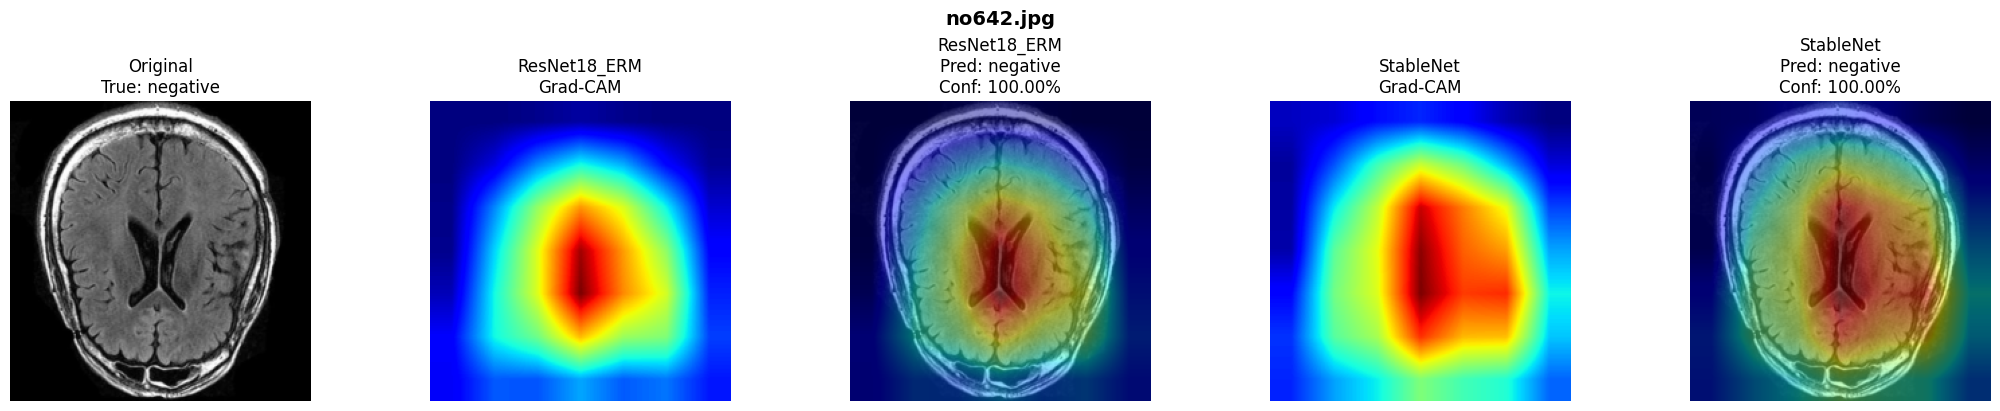

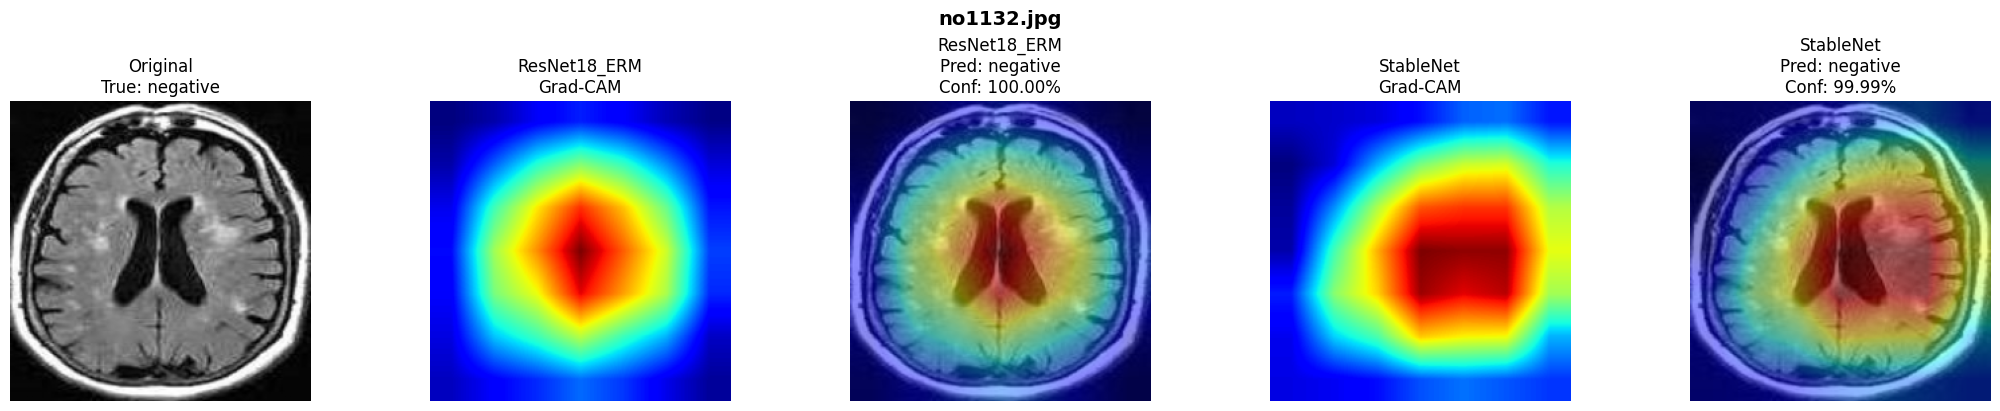

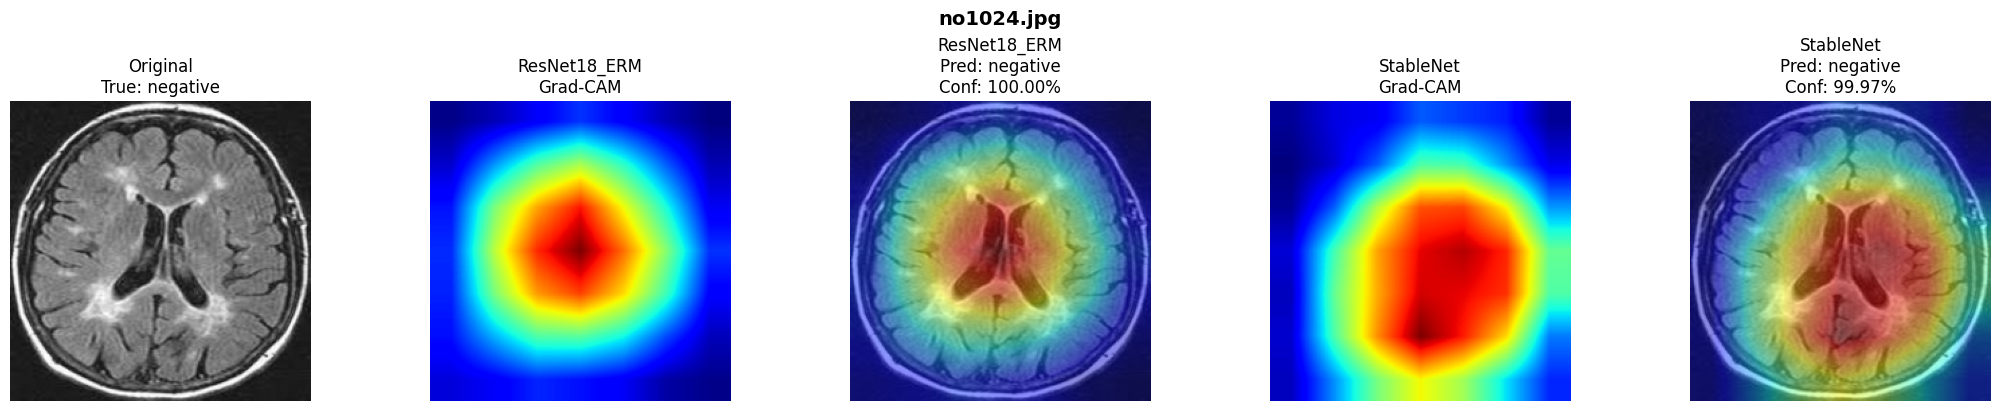

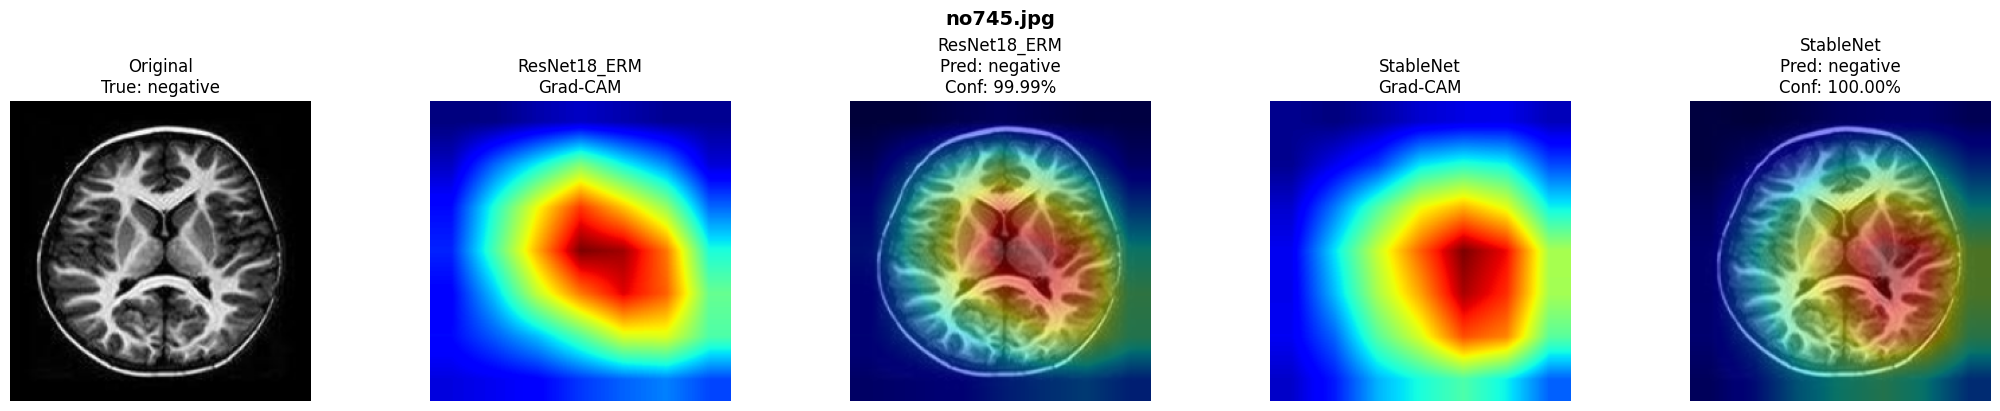

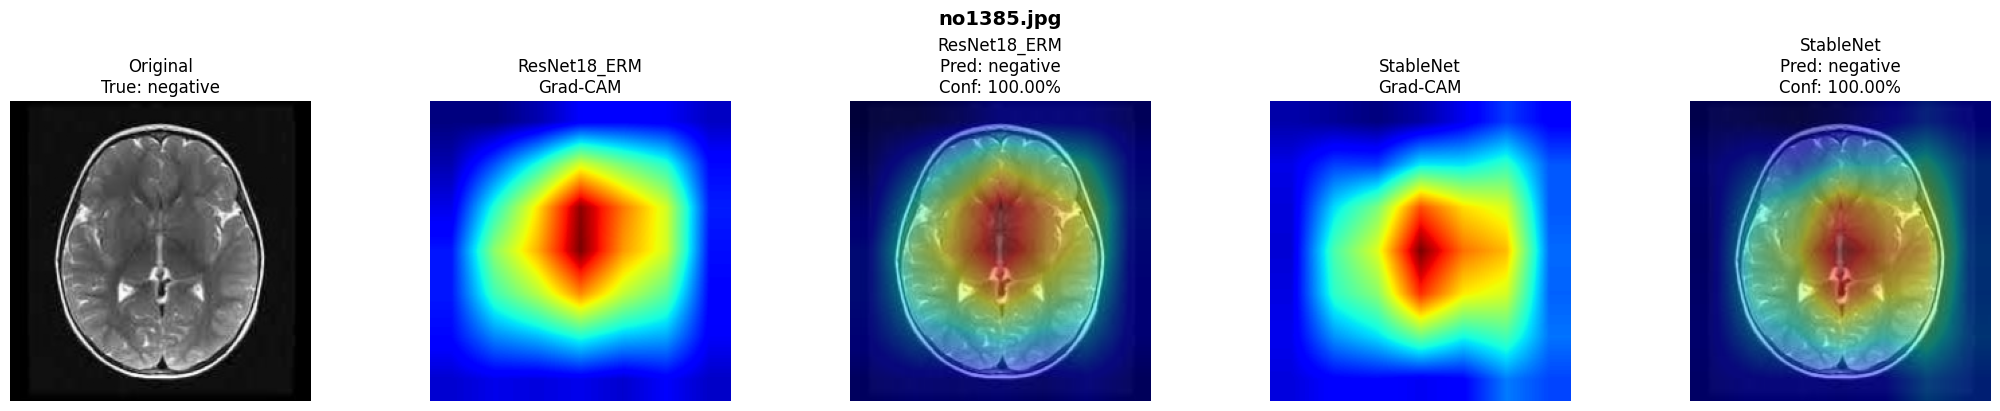

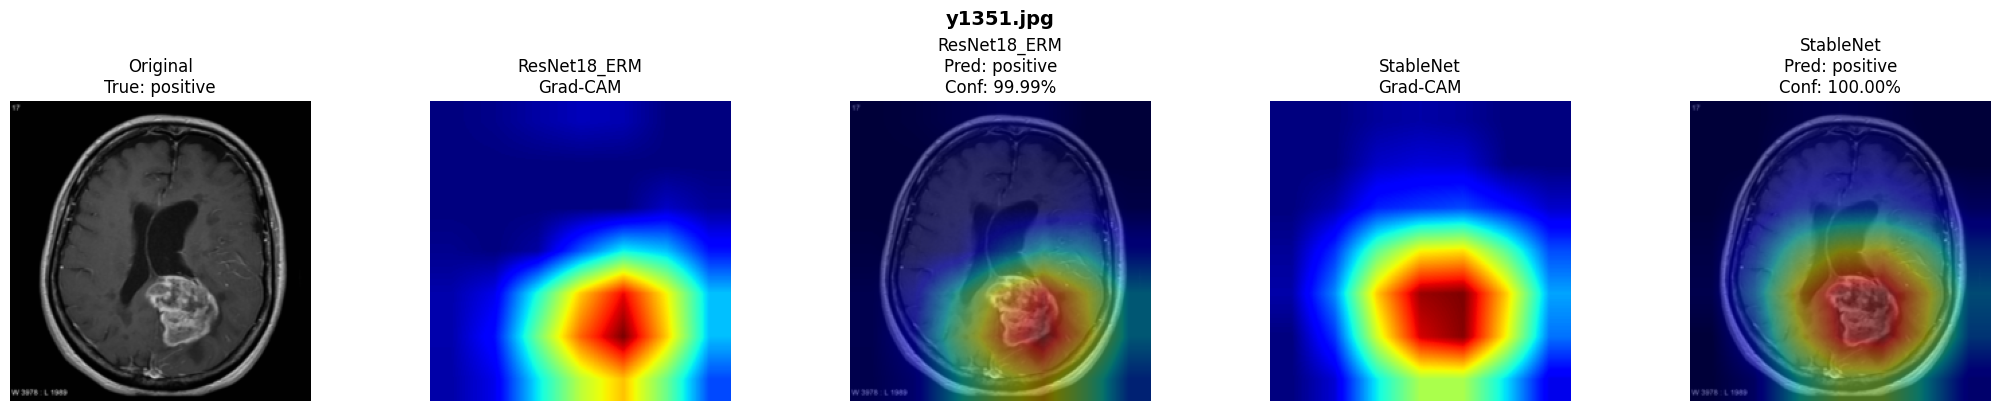

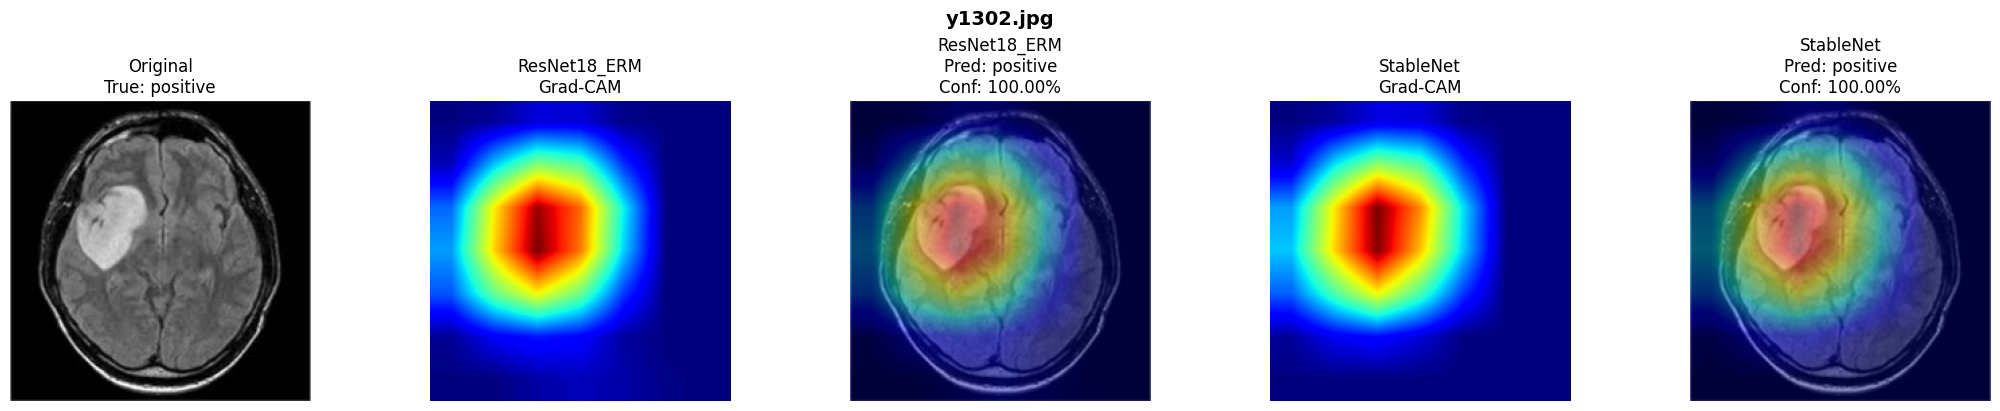

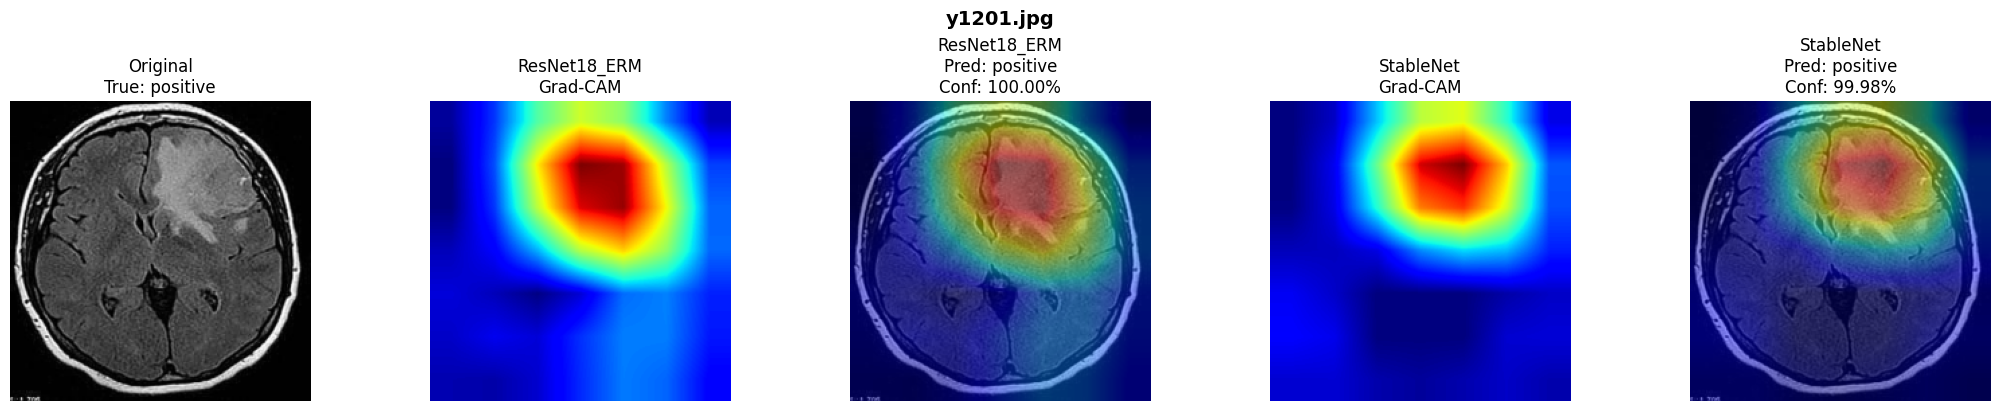

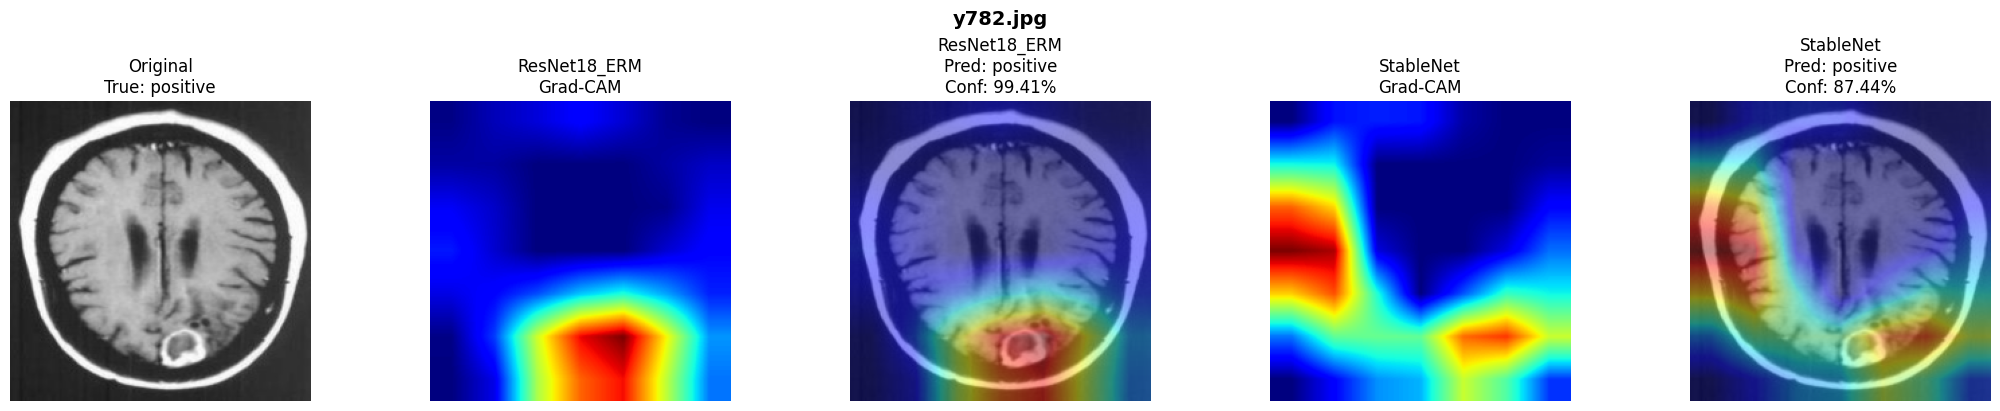

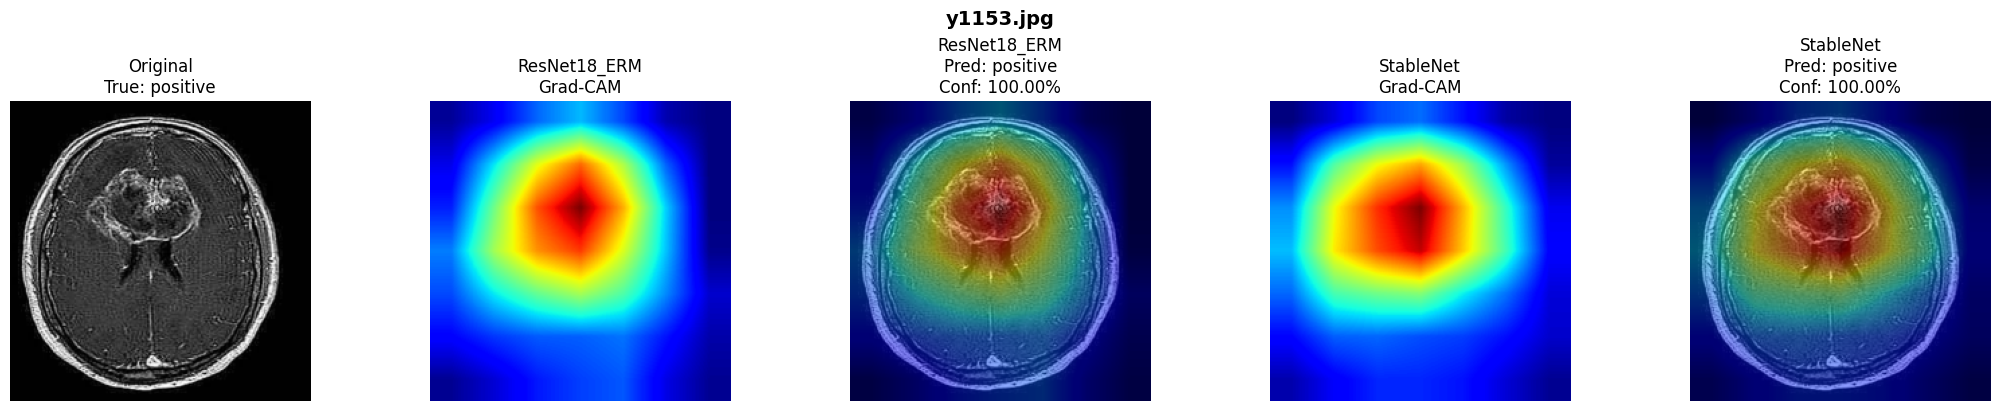

,image,true,method,predicted,confidence,correct
0,/root/autodl-tmp/medical_data/brain_tumor/test...,negative,ResNet18_ERM,negative,99.996613,True
1,/root/autodl-tmp/medical_data/brain_tumor/test...,negative,StableNet,negative,99.997543,True
2,/root/autodl-tmp/medical_data/brain_tumor/test...,negative,ResNet18_ERM,negative,99.999985,True
3,/root/autodl-tmp/medical_data/brain_tumor/test...,negative,StableNet,negative,99.992958,True
4,/root/autodl-tmp/medical_data/brain_tumor/test...,negative,ResNet18_ERM,negative,99.999962,True
5,/root/autodl-tmp/medical_data/brain_tumor/test...,negative,StableNet,negative,99.968315,True
6,/root/autodl-tmp/medical_data/brain_tumor/test...,negative,ResNet18_ERM,negative,99.991501,True
7,/root/autodl-tmp/medical_data/brain_tumor/test...,negative,StableNet,negative,99.999596,True
8,/root/autodl-tmp/medical_data/brain_tumor/test...,negative,ResNet18_ERM,negative,99.999031,True
9,/root/autodl-tmp/medical_data/brain_tumor/test...,negative,StableNet,negative,99.996758,True


In [11]:
cam_comparison_results = []

for image_path in cam_image_paths:
    true_class = image_path.parent.name
    figure, axes = plt.subplots(1, 5, figsize=(21, 4), constrained_layout=True)

    _, original_array = prepare_cam_image(image_path, cam_devices["ResNet18_ERM"])
    axes[0].imshow(original_array)
    axes[0].set_title(f"Original\nTrue: {true_class}")

    column = 1
    for method_name in ("ResNet18_ERM", "StableNet"):
        input_tensor, _ = prepare_cam_image(image_path, cam_devices[method_name])
        heatmap, predicted_class, probabilities = cam_engines[method_name](input_tensor)
        predicted_name = class_names[predicted_class]
        confidence = float(probabilities[predicted_class] * 100)
        color_heatmap = plt.get_cmap("jet")(heatmap)[..., :3]
        overlay = np.clip(0.55 * original_array + 0.45 * color_heatmap, 0, 1)

        axes[column].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
        axes[column].set_title(f"{method_name}\nGrad-CAM")
        axes[column + 1].imshow(overlay)
        axes[column + 1].set_title(
            f"{method_name}\nPred: {predicted_name}\nConf: {confidence:.2f}%"
        )
        column += 2

        cam_comparison_results.append({
            "image": str(image_path),
            "true": true_class,
            "method": method_name,
            "predicted": predicted_name,
            "confidence": confidence,
            "correct": predicted_name == true_class,
        })

    for axis in axes:
        axis.axis("off")
    figure.suptitle(image_path.name, fontsize=14, fontweight="bold")
    plt.show()

for engine in cam_engines.values():
    engine.close()

cam_results_df = pd.DataFrame(cam_comparison_results)
cam_results_df.to_csv(RUN_ROOT / "cam_comparison_results.csv", index=False)
display(cam_results_df)

### 如何解释对比结果

- 两种模型都关注病灶：说明它们可能都学习到了有意义的病灶特征。
- StableNet 比普通模型更集中于病灶：可以作为 StableNet 改善关注区域的定性证据。
- 两种模型都关注边框、颅骨或文字：说明数据来源捷径仍然存在。
- 预测正确但热区不在病灶：表示“答案正确”不等于“判断依据可靠”。Grad-CAM 是定性解释工具，不能代替独立测试集、病灶掩膜或医学专家评价。